# Herhalingslabo Classificatie

Hoe weet je wanneer je welk algoritme best gebruikt ? Gebruik volgende handleiding:

**KNearestNeighbours**
- Geschikt voor classificatie en regressie
- Voor kleine/middelgrote datasets
- heel simpel, kan snel worden getrained
- werkt niet goed voor datasets met heel veel features

**Support Vector Machines**
- Vooral een standaard voor binaire classificatie, of wanneer je een duidelijke marge wilt op classificatie (=het hoofddoel van het algoritme)
- Voor kleine/middelgrote datasets
- Is kostelijker om te trainen dan KNN, maar classificeert dan wel sneller
- Kernel keuze en hyperparameter tuning zijn essentieel

**Decision Trees**
- Wanneer je een 'white box', 'explainable' model wilt
- kan zowel numerieke als categorische features makkelijk aan
- kan heel goed om met missende datapunten
- het risico op overfitting is groot. Bij twijfel, gebruik een random forest

**Random forest**
- Zelfde voordelen als decision tree, minder risico op overfitting
- Geschikt voor middelgrote/grote datasets
- Geschikt voor data met (heel) veel features
- Hebben uiteraard meer trainingstijd nodig dan een enkele decision tree

**Adaboost**
- Als data niet goed is gebalanceerd (niet evenveel items van elke klasse)
- Vermijd een onderfit. Dit model is beter dan 1 enkele onderliggende decision tree

**XGBoost**
- XGBoost is bijna *altijd* een goede keuze
- Middelgrote / grote datasets
- Datasets met (heel) veel features
- De implementatie van XGBoost staat, ondanks dat het een boosting algoritme is, toch deels parallellisatie toe.

In de praktijk zijn er vaak meerdere goede keuzes. Het is belangrijk te weten waarom een bepaald model wel/niet een goede keuze zou zijn, en vervolgens de meest veelbelovende modellen te proberen en te kijken wat het beste werkt.

### Wat is een kleine / middelgrote / grote dataset ?

Uiteraard is dat een beetje afhankelijk van hoelang je bereid bent te wachten. In deze cursus gebruiken we de gangbare regel:
- Klein: <10k
- Middelgroot: 10k - 100k
- Groot: >100k

Dit is ongetwijfeld over een paar jaar volledig voorbijgestreefd. Besef dat je in real life dit altijd moet afwegen tegenover de beschikbare compute power, op een Raspberry Pi 3 zal een middelgrote dataset al een stevige trainingstijd hebben, terwijl dat kinderspel is op een cloud compute server.

## Oefeningen

Behandel de volgende 3 datasets - je kan ze downloaden vanop Digitap. Lees in, bekijk, en beoordeel welke algoritmes het meeste zin hebben. Pas de ML algoritmes toe en rapporteer de uiteindelijke score van je model.
- Diabetes - in de 'outcome' kolom wordt aangegeven of mensen diabetes hebben
- Customer Churn: in commerciële setting wordt vaak gesproken van 'churn', oftewel het aangeven in een soort diagram waar klanten in een process afhaken. Deze dataset bevat een 'churn' kolom die dat codeert.
- Creditcard bevat data die reeds door een ander algoritme is gegaan, waardoor de kolommen geen herkenbare naam meer hebben. De laatste kolom wijst op fraude (1) of een valide transactie (0).

### Diabetes

In [1]:
# Libraries inladen
import numpy as np
import pandas as pd
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report, confusion_matrix

# diabates dataset inladen (kan ook via pd.read_csv op de csv van digitap)
diabetes = pd.read_csv('data/diabetes.csv')

# features en labels eruit vissen
X = diabetes.drop(columns=['Outcome'])
y = diabetes['Outcome']

# Data splitten
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model fitten
model = SVC(kernel='linear') 
model.fit(X_train, y_train)

# Voorspellingen
y_pred = model.predict(X_test)

# Evaluatie
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")
print("Confusion Matrix:")
print(conf_matrix)
print("Classification Report:")
print(class_report)


Accuracy: 0.75
Confusion Matrix:
[[80 19]
 [19 36]]
Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.81      0.81        99
           1       0.65      0.65      0.65        55

    accuracy                           0.75       154
   macro avg       0.73      0.73      0.73       154
weighted avg       0.75      0.75      0.75       154



Hieronder wat extra code om de confusion matrix beter te visualiseren

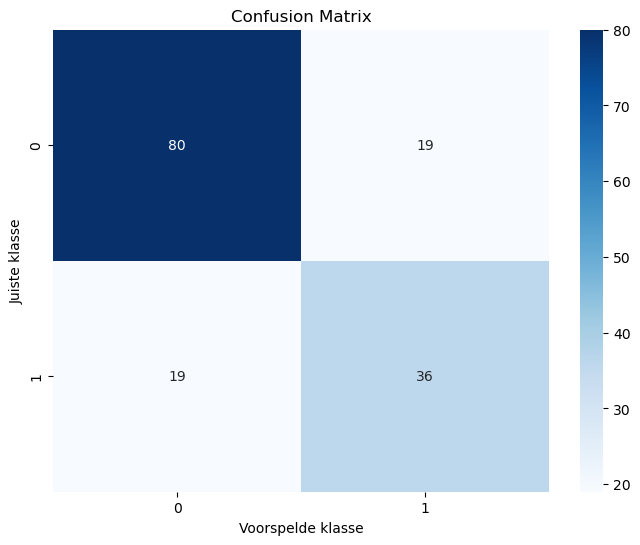

In [3]:
# Plotten van de tabel
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Voorspelde klasse")
plt.ylabel("Juiste klasse")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
#zelfde met KNN:
# Libraries inladen
import numpy as np
import pandas as pd
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report, confusion_matrix

# diabates dataset inladen (kan ook via pd.read_csv op de csv van digitap)
diabetes = pd.read_csv('data/diabetes.csv')

# features en labels eruit vissen
X = diabetes.drop(columns=['Outcome'])
y = diabetes['Outcome']

# Data splitten
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model fitten
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)

# Voorspellingen
y_pred = model.predict(X_test)

# Evaluatie
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")
print("Confusion Matrix:")
print(conf_matrix)
print("Classification Report:")
print(class_report)

Accuracy: 0.66
Confusion Matrix:
[[70 29]
 [23 32]]
Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.71      0.73        99
           1       0.52      0.58      0.55        55

    accuracy                           0.66       154
   macro avg       0.64      0.64      0.64       154
weighted avg       0.67      0.66      0.67       154



Mogelijke verbeteringen:
- standardscaler toepassen
- Grid search op parameters van SVC
- grid search op parameters van KNN

### Churn

Bij deze dataset heb ik de preprocessor meer uitgewerkt. Goede keuzes voor algoritmes: KNN, SVC, Random Forest (die is gebaseerd op decision trees en dus deels een 'white box', dan kan in deze handig zijn omdat marketeers / directie dan weet op welke parameters ze misschien best moeten inzetten om uitval te vermijden). XGBoost uiteraard ook altijd een goede optie.

Als je een ensemble method kiest; opletten met het aantal onderliggende estimators. Als er maar 250 datapunten zijn, is het bijna gegarandeerd dat een ensemble methode met 500 onderliggende classifiers gaat overfitten (want 500 > 250).

In [ ]:
# Libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Data inlezen
churn_data = pd.read_csv('data/customer_churn.csv')

# Data preprocessing: sommige features zijn niet numeriek, dus er is werk te doen

# Features en labels
X = churn_data.drop(columns=['Churn'])
y = churn_data['Churn']

# Trucje om snel numerieke en niet-numerieke features te vinden
numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
# Identify categorical features by checking the data type
categorical_features = X.select_dtypes(include=['object']).columns.tolist()


# Pipeline opzetten
numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())  # Standardisatie
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))  # OH encoding voor categorische features
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# Split 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# pipeling: preprocessing and model, we kiezen hier voor Random Forest
model = Pipeline([
    ('preprocessor', preprocessor),  # Preprocessing steps
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))  # RandomForest Classifier
])
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluatie
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")
print("Confusion Matrix:")
print(conf_matrix)
print("Classification Report:")
print(class_report)


Accuracy: 0.80
Confusion Matrix:
[[951  85]
 [202 171]]
Classification Report:
              precision    recall  f1-score   support

          No       0.82      0.92      0.87      1036
         Yes       0.67      0.46      0.54       373

    accuracy                           0.80      1409
   macro avg       0.75      0.69      0.71      1409
weighted avg       0.78      0.80      0.78      1409



### Creditcard
Dit is een grotere dataset. KNN, SVM vallen dus al uit de boot.

Deze data is bovendien heel ongebalanceerd, er zijn slechts 500-tal frauduleuze transacties. Adaboost verdient hier dan een poging. We gaan ook vergelijken met XGBoost.

In [ ]:
# Libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Dataset inlezen
creditcard_data = pd.read_csv('data/creditcard.csv')

# Data preprocessing
# De data is al gepreprocessed, dus dat is op dat vlak eenvoudig

# features, labels
X = creditcard_data.drop(columns=['Class'])
y = creditcard_data['Class']

# split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# adaboost
ada_model = AdaBoostClassifier(n_estimators=50, random_state=42)
ada_model.fit(X_train, y_train)

# XGBoost
xgb_model = XGBClassifier(n_estimators=50, random_state=42)
xgb_model.fit(X_train, y_train)

# poredictions
y_pred_ada = ada_model.predict(X_test)
y_pred_xgb = xgb_model.predict(X_test)

# Evaluatie
accuracy_ada = accuracy_score(y_test, y_pred_ada)
conf_matrix_ada = confusion_matrix(y_test, y_pred_ada)
class_report_ada = classification_report(y_test, y_pred_ada)

accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
conf_matrix_xgb = confusion_matrix(y_test, y_pred_xgb)
class_report_xgb = classification_report(y_test, y_pred_xgb)

print("AdaBoost Results:")
print(f"Accuracy: {accuracy_ada:.2f}")
print("Confusion Matrix:")
print(conf_matrix_ada)
print("Classification Report:")
print(class_report_ada)

print("\nXGBoost Results:")
print(f"Accuracy: {accuracy_xgb:.2f}")
print("Confusion Matrix:")
print(conf_matrix_xgb)
print("Classification Report:")
print(class_report_xgb)


AdaBoost Results:
Accuracy: 1.00
Confusion Matrix:
[[56852    12]
 [   27    71]]
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.86      0.72      0.78        98

    accuracy                           1.00     56962
   macro avg       0.93      0.86      0.89     56962
weighted avg       1.00      1.00      1.00     56962


XGBoost Results:
Accuracy: 1.00
Confusion Matrix:
[[56862     2]
 [   21    77]]
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.97      0.79      0.87        98

    accuracy                           1.00     56962
   macro avg       0.99      0.89      0.93     56962
weighted avg       1.00      1.00      1.00     56962



In [ ]:
print("Classification Report:")
print(class_report_xgb)


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.97      0.79      0.87        98

    accuracy                           1.00     56962
   macro avg       0.99      0.89      0.93     56962
weighted avg       1.00      1.00      1.00     56962



Merk op dat de accuracy in geval van deze cases niet alles zegt. Je hebt de confusion matrix en/of classification report nodig om te kunnen inzien dat XGBoost een heel stuk minder fouten maakt op de 1-labels, dus exact op die gevallen die we willen detecteren. Dat is een belangrijk gegeven!